## 0.Librerias y Funciones

#### Librerias

In [1]:
import warnings
warnings.filterwarnings('ignore')
import pandas as pd
import numpy as np
pd.options.mode.chained_assignment = None 
import os
import sys
import lightgbm as lgb
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import SGDRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
pd.options.display.max_rows=100
pd.options.display.max_columns=500

In [2]:
os.getcwd()

'C:\\Users\\KEVIN\\Downloads\\DSRP\\Machine Learning III\\DSRP_MLE3\\notebooks'

In [3]:
PROCESSED_DATA_DIR = "../data/processed/"

#### Funciones

In [4]:
import sbp_modelo as sbp

---

## 1.Lectura de datos

In [5]:
df = pd.read_parquet(PROCESSED_DATA_DIR+"processed.parquet")
print(df.shape)

(6362604, 9)


In [6]:
df.head()

,base,type,amount,entTrxType,oldbalanceOrg,origTrxAmount,oldbalanceDest,destTrxAmount,isFraud
0,0,PAYMENT,9839.64,CM,170136.0,-9839.64,0.0,NaN,0
1,0,PAYMENT,1864.28,CM,21249.0,-1864.28,0.0,NaN,0
2,0,TRANSFER,181.00,CC,181.0,-181.00,0.0,0.0,1
3,0,CASH_OUT,181.00,CC,181.0,-181.00,21182.0,-21182.0,1
4,0,PAYMENT,11668.14,CM,41554.0,-11668.14,0.0,NaN,0


In [7]:
df_desarrollo = df[df['base'] == 0]
df_produccion = df[df['base'] == 2]

In [8]:
target = 'isFraud'
seed = 666

In [9]:
df_train, df_test = train_test_split(df_desarrollo, test_size=0.2, random_state=seed, shuffle=True, stratify=df_desarrollo[target])

In [10]:
print('Total:', df.shape)
print('Desarrollo:', df_desarrollo.shape)
print('Train:', df_train.shape)
print('Test:', df_test.shape)
print('Produccion:', df_produccion.shape)

Total: (6362604, 9)
Desarrollo: (5787026, 9)
Train: (4629620, 9)
Test: (1157406, 9)
Produccion: (575578, 9)


---

## 2. Procesamiento

### 2.0. EDA

In [11]:
columnas_textuales = df_train.select_dtypes(include=['object', 'string', 'category']).columns
print(columnas_textuales)

Index(['type', 'entTrxType'], dtype='object')


In [12]:
lista_var_excl = ['base']
lista_var_cat = columnas_textuales.tolist()
ruta_eda = "eda/"
target = 'isFraud'

In [13]:
sbp.eda_vf2(df=df_train,target=target,var_excluidas=lista_var_excl,var_categoricas=lista_var_cat,ruta_eda=ruta_eda)

..Eda
.Correlacion
....1. amount
....2. destTrxAmount
....3. entTrxType
....4. oldbalanceDest
....5. oldbalanceOrg
....6. origTrxAmount
....7. type
Tiempo transcurrido: 2 minutos y 7.584 segundos


---

### 2.1. Tratamiento de variables numéricas

In [14]:
df_train.head()

,base,type,amount,entTrxType,oldbalanceOrg,origTrxAmount,oldbalanceDest,destTrxAmount,isFraud
5508643,0,CASH_OUT,19951.73,CC,49660.00,-19951.73,0.00,19951.73,0
2321526,0,PAYMENT,6357.25,CM,56503.00,-6357.25,0.00,NaN,0
4111006,0,CASH_IN,107883.86,CC,3488609.81,107883.86,885589.22,-107883.86,0
2716783,0,PAYMENT,6514.55,CM,31372.00,-6514.55,0.00,NaN,0
2137572,0,PAYMENT,2422.66,CM,0.00,0.00,0.00,NaN,0


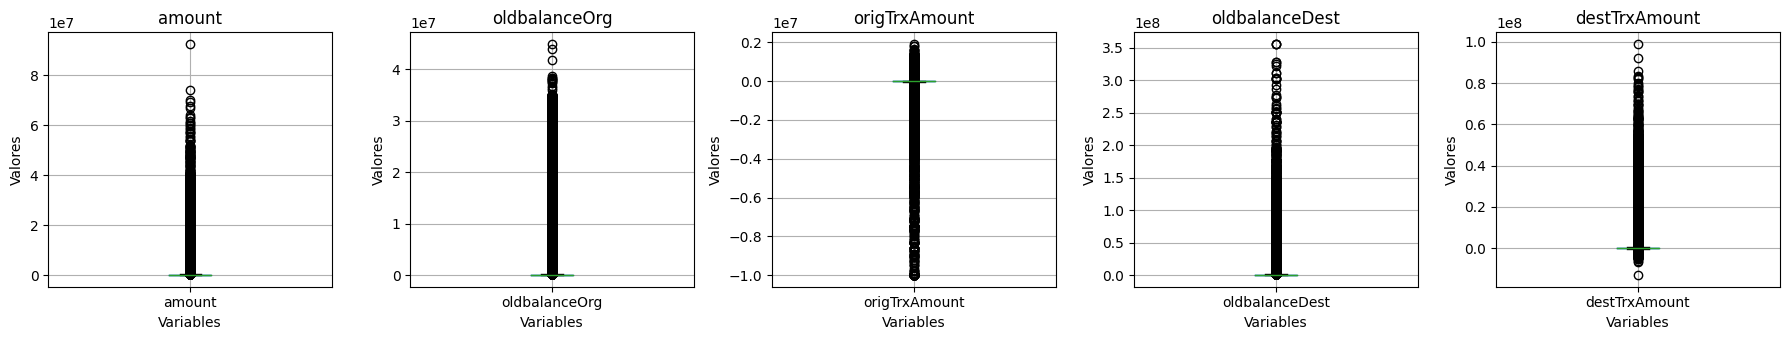

In [15]:
cols_num = ['amount','oldbalanceOrg','origTrxAmount','oldbalanceDest','destTrxAmount']
sbp.box_plot_outliers(df_train, cols_num)

In [16]:
df_outliers = df_train[cols_num]

percentil_99 = df_outliers.quantile(0.9999)
percentil_1 = df_outliers.quantile(0.0001)

cantidad_mayor_99 = (df_outliers > percentil_99).sum()
cantidad_menor_1 = (df_outliers < percentil_1).sum()

resultados = pd.DataFrame({
    'Percentil 99.99%': percentil_99,
    'Percentil 0.01%': percentil_1,
    'Cantidad Mayor al Percentil 99.99%': cantidad_mayor_99,
    'Cantidad Menor al Percentil 0.01%': cantidad_menor_1
})

resultados

,Percentil 99.99%,Percentil 0.01%,Cantidad Mayor al Percentil 99.99%,Cantidad Menor al Percentil 0.01%
amount,2.413252e+07,4.909619e+00,463,463
oldbalanceOrg,3.119145e+07,0.000000e+00,463,0
origTrxAmount,7.913401e+05,-3.354201e+06,463,463
oldbalanceDest,1.088845e+08,0.000000e+00,463,0
destTrxAmount,3.943568e+07,-1.158047e+06,308,308


### 2.2. Tratamiento de variables categóricas

In [17]:
columnas_textuales = df_train.select_dtypes(include=['object', 'string', 'category']).columns
print(columnas_textuales)

Index(['type', 'entTrxType'], dtype='object')


In [18]:
lista_var_categ = ['type','entTrxType']
for i in lista_var_categ:
    print(i," ==> ",df_train[i].unique())
    print("------------------------------------------------------------------------------------------------")

type  ==>  ['CASH_OUT' 'PAYMENT' 'CASH_IN' 'TRANSFER' 'DEBIT']
------------------------------------------------------------------------------------------------
entTrxType  ==>  ['CC' 'CM']
------------------------------------------------------------------------------------------------


##### 2.1.2. Variables Nominales

In [19]:
lista_var_nominales = ['type','entTrxType']

In [20]:
# Imputamos NaN por la categoría 'Missing' y convertimos los tipos de variables nominales
for i in lista_var_nominales:
  df_train[i] = df_train[i].fillna('Missing')
  df_train[i] = df_train[i].astype('category')
  df_test[i] = df_test[i].fillna('Missing')
  df_test[i] = df_test[i].astype('category')

### 2.3. Preselección de variables

In [21]:
print("Número de variables: ",df_train.shape[1])
print("Número de registros: ",df_train.shape[0])

Número de variables:  9
Número de registros:  4629620


---

##### 2.2.1. Variables iniciales

In [22]:
# Quitando variables no predictivas
variables_a_eliminar=['base']
df_train.drop(variables_a_eliminar, inplace=True, axis=1)
df_test.drop(variables_a_eliminar, inplace=True, axis=1)
print("Número de variables: ",df_train.shape[1])
print("\nVariables eliminadas: ", len(variables_a_eliminar),"==>" , variables_a_eliminar)

Número de variables:  8

Variables eliminadas:  1 ==> ['base']


##### 2.2.1. Variables con alto porcentaje de missing

In [23]:
missing_df_train = pd.DataFrame(df_train.isnull().sum())
missing_df_train = missing_df_train.rename(index=str, columns={0: 'cant_missing'})
missing_df_train['porc_missing'] = missing_df_train['cant_missing']*100/len(df_train)
missing_df_train = missing_df_train.sort_values(by='porc_missing', ascending=False)
missing_df_train.query("porc_missing>=90")

,cant_missing,porc_missing


In [24]:
# Eliminamos variables con mucho missing
umbral_missing = 95

missing_df_train.reset_index()
quitar_missing = missing_df_train[missing_df_train['porc_missing'] > umbral_missing]
df_train.drop(quitar_missing.index, inplace=True, axis=1)
df_test.drop(quitar_missing.index, inplace=True, axis=1)

print("Número de variables: ",df_train.shape[1])
print("\nVariables eliminadas: ", len(quitar_missing.index.to_list()),"==>" , quitar_missing.index.to_list())

Número de variables:  8

Variables eliminadas:  0 ==> []


---

## Export

In [25]:
print(df_train.shape)
print(df_test.shape)

(4629620, 8)
(1157406, 8)


In [26]:
df_train.to_parquet(PROCESSED_DATA_DIR+"train.parquet",engine='pyarrow',compression='GZIP')
df_test.to_parquet(PROCESSED_DATA_DIR+"test.parquet",engine='pyarrow',compression='GZIP')